# Training LSTM Model to Process Reviews

### Import Required Libraries

This cell imports all necessary libraries for building and training the LSTM model:
- **Data handling**: pandas, numpy for data manipulation
- **Visualization**: matplotlib, seaborn for plotting training results
- **Machine learning**: sklearn for data splitting, evaluation metrics, and class weight computation
- **Deep learning**: TensorFlow/Keras for building the neural network
- **Utilities**: re, warnings for various helper functions

In [73]:
import re
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import tensorflow as tf

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.utils.class_weight import compute_class_weight
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau # type: ignore
from tensorflow.keras.layers import ( # type: ignore
    Embedding, LSTM, Dense, Dropout, Bidirectional, LayerNormalization
)
from tensorflow.keras.models import Sequential # type: ignore
from tensorflow.keras.optimizers import Adam # type: ignore
from tensorflow.keras.regularizers import l2 # type: ignore

### Optimizer Selection

Choose from different optimizers to experiment with model performance. Each has different characteristics:
- **Adam**: Popular general-purpose optimizer, combines momentum and adaptive learning (default choice)
- **RMSprop**: Good for recurrent networks and CNNs, adapts learning rate
- **SGD**: Classic optimizer with momentum, often performs well with proper tuning
- **Nadam**: Adam with Nesterov momentum for better convergence
- **AdamW**: Adam with weight decay for better regularization (requires tensorflow-addons)

### LSTM Class Definition

This cell contains:
1. **Optimizer dictionary**: Clean configuration of all available optimizers
2. **Optimizer selection**: Easy switching between optimizers by changing one variable
3. **SentimentLSTM class**: Complete LSTM architecture with bidirectional layers, layer normalization, and dropout for sentiment analysis

In [74]:
# Optimizer configurations
optimizers = {
    'adam': tf.keras.optimizers.Adam(learning_rate=0.001, beta_1=0.9, beta_2=0.999),
    'rmsprop': tf.keras.optimizers.RMSprop(learning_rate=0.001),
    'sgd': tf.keras.optimizers.SGD(learning_rate=0.01, momentum=0.9, nesterov=True),
    'nadam': tf.keras.optimizers.Nadam(learning_rate=0.001),
    # 'adamw': tfa.optimizers.AdamW(learning_rate=0.001, weight_decay=1e-4)  # requires tensorflow-addons
}

# Choose optimizer
chosen_optimizer = 'adam'  
optimizer = optimizers[chosen_optimizer]

print(f"Using optimizer: {optimizer.__class__.__name__}")

class SentimentLSTM:
    def __init__(self, vocab_size, num_classes=3, embedding_dim=128, input_length=60, lstm_units=128, dropout_rate=0.2, l2_rate=0.01, learning_rate=0.0003):
        self.vocab_size = vocab_size
        self.num_classes = num_classes
        self.embedding_dim = embedding_dim
        self.input_length = input_length
        self.lstm_units = lstm_units
        self.dropout_rate = dropout_rate
        self.l2_rate = l2_rate
        self.learning_rate = learning_rate
        
        self.build_model()
        self.compile_model()
        
    def build_model(self):
        self.model = Sequential([
            Embedding(input_dim=self.vocab_size, output_dim=self.embedding_dim, input_length=self.input_length),
            
            Bidirectional(LSTM(self.lstm_units, return_sequences=True)),
            Dropout(self.dropout_rate),
            LayerNormalization(),
            
            Bidirectional(LSTM(self.lstm_units)),
            Dropout(self.dropout_rate),
            LayerNormalization(),
            
            Dense(128, activation='relu', kernel_regularizer=l2(self.l2_rate)),
            Dropout(self.dropout_rate),
            
            Dense(64, activation='relu', kernel_regularizer=l2(self.l2_rate)),
            Dropout(self.dropout_rate),
            
            Dense(self.num_classes, activation='softmax'),
        ])
        
    def compile_model(self):
        self.model.compile(optimizer=optimizer, loss='sparse_categorical_crossentropy', metrics=['accuracy'])

    def train(self, X_train, y_train, X_val, y_val, epochs=30, batch_size=64,  callbacks=None, lr_scheduler=None, class_weight=None):
        early_stop = EarlyStopping(
            monitor='val_loss',
            patience=3,
            restore_best_weights=True,
            verbose=1
        )
        
        lr_scheduler = ReduceLROnPlateau(
            monitor='val_loss', 
            factor=0.5, 
            patience=2, 
            min_lr=1e-6, 
            verbose=1
        )
        
        checkpoint = ModelCheckpoint(
            filepath='../../models/sentiment_lstm_model.h5',
            monitor='val_loss',
            save_best_only=True,
            mode='min',
            verbose=1
        )
        
        return self.model.fit(
            X_train, 
            y_train,
            validation_data=(X_val, y_val),
            epochs=epochs,
            batch_size=batch_size,
            callbacks=[early_stop, lr_scheduler, checkpoint],
            class_weight=class_weight
        )
    
    def evaluate(self, X_test, y_test):
        return self.model.evaluate(X_test, y_test, verbose=0)

    def predict(self, X):
        return np.argmax(self.model.predict(X), axis=1)
    
    def summary(self):
        self.model.summary()

Using optimizer: Adam


### Load and Display Preprocessed Data

Load the tokenized and padded dataset that was prepared in the preprocessing stage. This data contains:
- **Padded sequences**: Reviews converted to integer sequences with consistent length
- **Numerical labels**: Sentiment labels encoded as integers (0=negative, 1=neutral, 2=positive)

In [75]:
def fix_and_parse_padded(padded_data):
    if isinstance(padded_data, list):  # already a list
        return padded_data
    if isinstance(padded_data, str):   # it's a string that needs parsing
        cleaned = re.sub(r'\s+', ',', padded_data.strip('[]'))
        return [int(num) for num in cleaned.split(',') if num.strip().isdigit()]
    return []  # fallback for invalid data

In [76]:
df = pd.read_csv('../../data/processed_reviews_dl.csv')
display(df.head())

,review,language,label,label_numerical,tokenized,padded
0,terrible,en,negative,0,[364],[364 0 0 0 0 0 0 0 0 0 0 ...
1,less movie show total money worst,en,negative,0,"[609, 337, 316, 2655, 244, 77]",[ 609 337 316 2655 244 77 0 0 0 ...
2,inapt brightness cannot brought zero even phon...,en,negative,0,"[5233, 1362, 760, 3462, 1579, 165, 367, 1362, ...",[5233 1362 760 3462 1579 165 367 1362 1867 ...
3,able login account tried uninstalling reinstat...,en,negative,0,"[798, 871, 223, 389, 2656, 3463, 18, 263, 2071...",[ 798 871 223 389 2656 3463 18 263 2071 ...
4,netflix one favourite platform watch show prob...,en,negative,0,"[231, 70, 1580, 617, 458, 316, 134, 231, 1307,...",[ 231 70 1580 617 458 316 134 231 1307 ...


### Data Processing and Analysis

This cell performs several critical data preprocessing steps:
1. **Parse padded sequences**: Convert string representations back to integer lists
2. **Extract features and labels**: Prepare input arrays and label arrays
3. **Set class labels**: Define sentiment class names for visualization

In [77]:
# Parse the padded column
df['padded'] = df['padded'].apply(fix_and_parse_padded)
display(df)

,review,language,label,label_numerical,tokenized,padded
0,terrible,en,negative,0,[364],"[364, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0..."
1,less movie show total money worst,en,negative,0,"[609, 337, 316, 2655, 244, 77]","[609, 337, 316, 2655, 244, 77, 0, 0, 0, 0, 0, ..."
2,inapt brightness cannot brought zero even phon...,en,negative,0,"[5233, 1362, 760, 3462, 1579, 165, 367, 1362, ...","[5233, 1362, 760, 3462, 1579, 165, 367, 1362, ..."
3,able login account tried uninstalling reinstat...,en,negative,0,"[798, 871, 223, 389, 2656, 3463, 18, 263, 2071...","[798, 871, 223, 389, 2656, 3463, 18, 263, 2071..."
4,netflix one favourite platform watch show prob...,en,negative,0,"[231, 70, 1580, 617, 458, 316, 134, 231, 1307,...","[231, 70, 1580, 617, 458, 316, 134, 231, 1307,..."
...,...,...,...,...,...,...
22231,رغم ان ب عجب ناس ك تير ل كن ارا قيم مقابل ك مي...,ar,neutral,1,"[376, 10, 5, 1, 344, 7, 1836, 4, 20, 4824, 958...","[376, 10, 5, 1, 344, 7, 1836, 4, 20, 4824, 958..."
22232,ال اكل جميل جدا,ar,neutral,1,"[2, 23, 45, 9]","[2, 23, 45, 9, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0..."
22233,ال دجاج و اللحوم مثلج,ar,neutral,1,"[2, 50, 3, 4820, 4096]","[2, 50, 3, 4820, 4096, 0, 0, 0, 0, 0, 0, 0, 0,..."
22234,ممتاز ب ل و يفتح ب المدين يصير امتز,ar,neutral,1,"[25, 5, 4, 3, 1417, 5, 8717, 1058, 1]","[25, 5, 4, 3, 1417, 5, 8717, 1058, 1, 0, 0, 0,..."


In [78]:
# Extract features and labels
X = np.array(df['padded'].tolist())
y = np.array(df['label_numerical'])
class_labels = ['negative', 'neutral', 'positive']

print(f"\nPreprocessing complete")
print(f"X shape: {X.shape}")
print(f"y shape: {y.shape}")
df.head()


Preprocessing complete
X shape: (22236, 60)
y shape: (22236,)


,review,language,label,label_numerical,tokenized,padded
0,terrible,en,negative,0,[364],"[364, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0..."
1,less movie show total money worst,en,negative,0,"[609, 337, 316, 2655, 244, 77]","[609, 337, 316, 2655, 244, 77, 0, 0, 0, 0, 0, ..."
2,inapt brightness cannot brought zero even phon...,en,negative,0,"[5233, 1362, 760, 3462, 1579, 165, 367, 1362, ...","[5233, 1362, 760, 3462, 1579, 165, 367, 1362, ..."
3,able login account tried uninstalling reinstat...,en,negative,0,"[798, 871, 223, 389, 2656, 3463, 18, 263, 2071...","[798, 871, 223, 389, 2656, 3463, 18, 263, 2071..."
4,netflix one favourite platform watch show prob...,en,negative,0,"[231, 70, 1580, 617, 458, 316, 134, 231, 1307,...","[231, 70, 1580, 617, 458, 316, 134, 231, 1307,..."


### Data Splitting

Split the dataset into training, validation, and test sets with stratification to maintain class balance across all splits.

In [79]:
# Split the data
X_train_full, X_test, y_train_full, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)

X_train, X_val, y_train, y_val = train_test_split(
    X_train_full, y_train_full, test_size=0.25,  stratify=y_train_full, random_state=42)

# Print data splitting info
print(f"\nData split:")
print(f"Training set: {X_train.shape[0]} samples")
print(f"Validation set: {X_val.shape[0]} samples") 
print(f"Test set: {X_test.shape[0]} samples")


Data split:
Training set: 13341 samples
Validation set: 4447 samples
Test set: 4448 samples


### Model Initialization

Create and initialize the LSTM model with the calculated parameters from our dataset. The model uses:
- **Bidirectional LSTM**: Captures patterns from both forward and backward sequences
- **Layer normalization**: For stable training and faster convergence  
- **Dropout**: For regularization to prevent overfitting
- **Sparse categorical crossentropy**: Efficient loss function for integer labels (no one-hot encoding needed)

In [80]:
# Determine number of unique classes
num_classes = len(np.unique(y))

# Get vocab size from the max token ID
vocab_size = np.max(X) + 1

# Set max sequence length (if you padded with maxlen=X)
max_length = X.shape[1]

# Initialize model
model = SentimentLSTM(
    vocab_size=vocab_size,
    input_length=max_length,
    num_classes=num_classes
)

# Display model architecture
# model.summary()

c:\Users\Nadaf\.pyenv\pyenv-win\versions\3.10.4\lib\site-packages\keras\src\layers\core\embedding.py:97: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


### Label Format Verification

Since we're using sparse categorical crossentropy, we work directly with integer labels instead of one-hot encoded vectors. This is more memory-efficient and computationally faster.

In [81]:
# Labels are already in integer format (0, 1, 2) - no need for one-hot encoding with sparse_categorical_crossentropy
print(f"Original y_train shape: {y_train.shape}")
print(f"y_val shape: {y_val.shape}")
print(f"y_test shape: {y_test.shape}")

# Example of label format
print(f"\nExample labels: {y_train[:5]} (integers, not one-hot)")

Original y_train shape: (13341,)
y_val shape: (4447,)
y_test shape: (4448,)

Example labels: [1 2 1 1 0] (integers, not one-hot)


### Compute Class Weights

Calculate balanced class weights to handle class imbalance in the dataset. This helps the model pay equal attention to all sentiment classes during training.

In [82]:
class_weights = compute_class_weight('balanced', classes=np.unique(y_train), y=y_train)
class_weight_dict = dict(enumerate(class_weights))

### Model Training

Train the LSTM model with the following configuration:
- **Early stopping**: Prevents overfitting by monitoring validation loss
- **Learning rate reduction**: Reduces learning rate when validation loss plateaus
- **Model checkpointing**: Saves the best model weights during training
- **Class weights**: Handle class imbalance for better performance across all sentiment classes
- **Integer labels**: Using sparse categorical crossentropy with original integer labels

In [83]:
# Train the model
print("Starting model training...")

history = model.train(
    X_train, 
    y_train, 
    X_val, 
    y_val, 
    epochs=30, 
    batch_size=64, 
    class_weight=class_weight_dict
)

print("\nTraining completed!")

Starting model training...
Epoch 1/30
209/209 ━━━━━━━━━━━━━━━━━━━━ 0s 251ms/step - accuracy: 0.6626 - loss: 2.5835
Epoch 1: val_loss improved from inf to 0.78472, saving model to ../../models/sentiment_lstm_model.h5


209/209 ━━━━━━━━━━━━━━━━━━━━ 73s 287ms/step - accuracy: 0.6633 - loss: 2.5795 - val_accuracy: 0.8916 - val_loss: 0.7847 - learning_rate: 0.0010
Epoch 2/30
209/209 ━━━━━━━━━━━━━━━━━━━━ 0s 235ms/step - accuracy: 0.9232 - loss: 0.5815
Epoch 2: val_loss improved from 0.78472 to 0.41022, saving model to ../../models/sentiment_lstm_model.h5


209/209 ━━━━━━━━━━━━━━━━━━━━ 55s 263ms/step - accuracy: 0.9232 - loss: 0.5811 - val_accuracy: 0.9029 - val_loss: 0.4102 - learning_rate: 0.0010
Epoch 3/30
209/209 ━━━━━━━━━━━━━━━━━━━━ 0s 233ms/step - accuracy: 0.9445 - loss: 0.2648
Epoch 3: val_loss improved from 0.41022 to 0.37616, saving model to ../../models/sentiment_lstm_model.h5


209/209 ━━━━━━━━━━━━━━━━━━━━ 55s 262ms/step - accuracy: 0.9445 - loss: 0.2647 - val_accuracy: 0.9076 - val_loss: 0.3762 - learning_rate: 0.0010
Epoch 4/30
209/209 ━━━━━━━━━━━━━━━━━━━━ 0s 232ms/step - accuracy: 0.9624 - loss: 0.1679
Epoch 4: val_loss did not improve from 0.37616
209/209 ━━━━━━━━━━━━━━━━━━━━ 54s 260ms/step - accuracy: 0.9624 - loss: 0.1680 - val_accuracy: 0.9069 - val_loss: 0.3874 - learning_rate: 0.0010
Epoch 5/30
209/209 ━━━━━━━━━━━━━━━━━━━━ 0s 275ms/step - accuracy: 0.9689 - loss: 0.1342
Epoch 5: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.

Epoch 5: val_loss did not improve from 0.37616
209/209 ━━━━━━━━━━━━━━━━━━━━ 64s 306ms/step - accuracy: 0.9689 - loss: 0.1342 - val_accuracy: 0.8999 - val_loss: 0.4250 - learning_rate: 0.0010
Epoch 6/30
209/209 ━━━━━━━━━━━━━━━━━━━━ 0s 234ms/step - accuracy: 0.9792 - loss: 0.0962
Epoch 6: val_loss did not improve from 0.37616
209/209 ━━━━━━━━━━━━━━━━━━━━ 55s 261ms/step - accuracy: 0.9792 - loss: 0.0962 - val_ac

### Model Evaluation and Visualization

Evaluate the trained model on the test set and visualize the training progress:
- **Test evaluation**: Get final accuracy and loss metrics on unseen data
- **Training curves**: Plot accuracy and loss progression during training
- **Performance analysis**: Visualize how well the model learned over epochs

Evaluating model on test set...

Test Loss: 0.3268
Test Accuracy: 91.84%


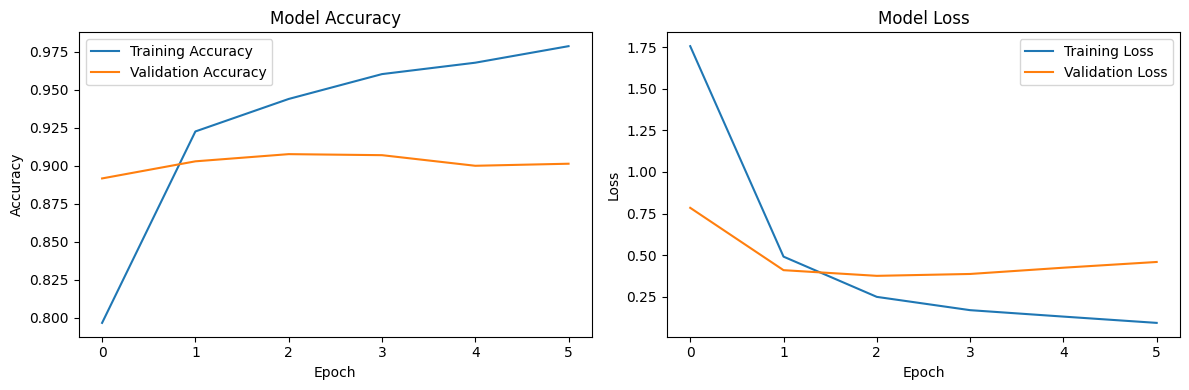

In [84]:
# Evaluate the model
print("Evaluating model on test set...")

# Convert X_test to 2D numpy array of int32
X_test_arr = np.stack(X_test).astype(np.int32)
X_test_arr = np.clip(X_test_arr, 0, vocab_size - 1)

# Use integer labels directly with sparse_categorical_crossentropy
loss, test_accuracy = model.evaluate(X_test_arr, y_test)
print(f"\nTest Loss: {loss:.4f}")
print(f"Test Accuracy: {test_accuracy * 100:.2f}%")

plt.figure(figsize=(12, 4))

# Plot training history
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

# Plot training & validation loss
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()

### Generate Predictions

Generate class predictions directly from the model output for detailed performance analysis.

In [85]:
y_true = y_test  # Use original integer labels
y_pred = model.predict(X_test_arr)

139/139 ━━━━━━━━━━━━━━━━━━━━ 8s 52ms/step


### Detailed Performance Analysis

Generate comprehensive performance metrics:
- **Classification report**: Detailed precision, recall, and F1-scores per class
- **Confusion matrix**: Visual representation of prediction accuracy per class
- **Performance summary**: Complete overview of model capabilities and results


Classification Report:
              precision    recall  f1-score   support

    negative       0.91      0.94      0.92      1474
     neutral       0.95      0.91      0.93      1500
    positive       0.90      0.91      0.90      1474

    accuracy                           0.92      4448
   macro avg       0.92      0.92      0.92      4448
weighted avg       0.92      0.92      0.92      4448



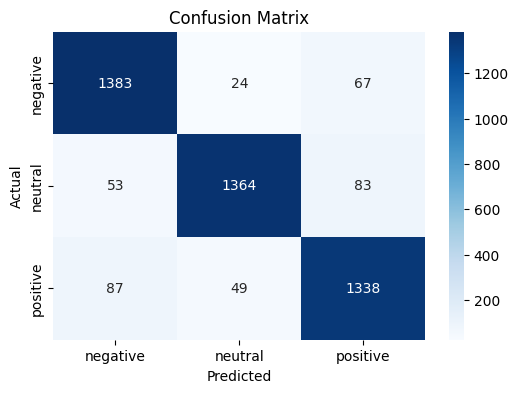


LSTM Model training completed successfully!
Final Test Accuracy: 0.9184 (91.84%)
Final Test Loss: 0.3268

Model Performance Summary:
- Vocabulary Size: 14,997
- Max Sequence Length: 60
- Training Samples: 13,341
- Validation Samples: 4,447
- Test Samples: 4,448
- Test Accuracy: 91.84%


In [86]:
print("\nClassification Report:")

print(classification_report(
    y_true, 
    y_pred, 
    target_names=class_labels, 
))

# Confusion Matrix
plt.figure(figsize=(6, 4))
cm = confusion_matrix(y_true, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=class_labels, yticklabels=class_labels)
plt.title('Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

print("\nLSTM Model training completed successfully!")
print(f"Final Test Accuracy: {test_accuracy:.4f} ({test_accuracy*100:.2f}%)")
print(f"Final Test Loss: {loss:.4f}")

# Summary of results
print("\nModel Performance Summary:")
print(f"- Vocabulary Size: {vocab_size:,}")
print(f"- Max Sequence Length: {max_length}")
print(f"- Training Samples: {len(X_train):,}")
print(f"- Validation Samples: {len(X_val):,}")
print(f"- Test Samples: {len(X_test):,}")
print(f"- Test Accuracy: {test_accuracy*100:.2f}%")